<a href="https://colab.research.google.com/github/Fdau0002/Permanent-Magnet-Temperature-Estimate/blob/feature%2Fpreprocessing-validation/Permanent_Magnet_Temperature_Estimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Engineering Interpretation

In [ ]:
import pandas as pd

# Upload the CSV file using the folder icon on the left first.
# Once uploaded, it will be available at this path:
df = pd.read_csv('PMSM Electric Motor Temperature Measurement.csv')

## 2.1 Dataset Description & Source

The dataset used in this investigation is the PMSM Electric Motor Temperature Measurement dataset, obtained from Kaggle and associated with Kirchgässner et al. (2021), Data-Driven Permanent Magnet Temperature Estimation in Synchronous Motors With Supervised Machine Learning: A Benchmark. The dataset contains measurements collected from a permanent magnet synchronous motor (PMSM) test bench operating at a sampling frequency of 2 Hz, corresponding to one observation every 0.5 seconds. The downloaded dataset contains 1,330,816 observations, 13 columns and 69 measurement profiles, representing approximately 184.84 hours of recorded motor operation. This is an expanded version of the dataset used in the original paper, which reported approximately 139 hours of measurements. Consequently, the published results will be used as reference benchmarks rather than targets for exact numerical reproduction.


In [ ]:
import pandas as pd
import os

path = "PMSM Electric Motor Temperature Measurement.csv"

print("File location:", os.path.abspath(path))
print("File size (MB):", os.path.getsize(path) / 1e6)

df = pd.read_csv(path)

print("Observations:", len(df))
print("Columns:", len(df.columns))
print("Unique profiles:", df["profile_id"].nunique())
print("Recording hours:", len(df) / (2 * 3600))

File location: /content/PMSM Electric Motor Temperature Measurement.csv
File size (MB): 292.552704
Observations: 1330087
Columns: 13
Unique profiles: 69
Recording hours: 184.73430555555555


## 2.2 Inputs & Outputs

Each observation contains measurements of the motor's electrical, mechanical and thermal operating conditions. The dataset includes variables such as motor speed, torque, electrical currents, voltages, coolant temperature and ambient temperature, alongside several measured component temperatures. The primary prediction target is the permanent-magnet temperature, represented by the pm column.

The intended computational output is an estimated magnet temperature PM obtained using supervised machine-learning regression. The profile_id column identifies individual motor-recording sessions and is used for data partitioning rather than as a predictive input. The final model input set will be defined using the relevant measured and derived variables described in Table I of Kirchgässner et al. (2021). Temporal features based on exponentially weighted moving averages (EWMA) and standard deviations (EWMS) will subsequently be introduced.


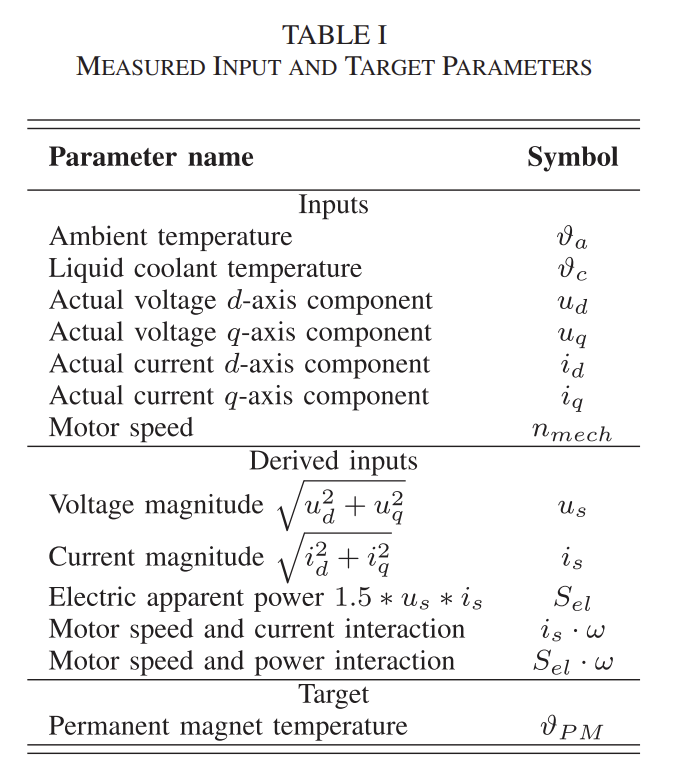

In [ ]:
profile_summary = (
    df.groupby("profile_id")
    .agg(
        observations=("pm", "size"),
        pm_min=("pm", "min"),
        pm_max=("pm", "max")
    )
    .reset_index()
)

profile_summary["duration_hours"] = (
    profile_summary["observations"] / (2 * 3600)
)

display(profile_summary)

,profile_id,observations,pm_min,pm_max,duration_hours
0,2.0,19357,22.970417,45.985561,2.688472
1,3.0,19248,22.751144,29.011612,2.673333
2,4.0,33424,22.924950,99.396629,4.642222
3,5.0,14788,25.889381,39.938965,2.053889
4,6.0,40388,24.349821,93.512962,5.609444
...,...,...,...,...,...
64,76.0,22188,31.433067,82.554532,3.081667
65,78.0,8445,21.266710,68.029359,1.172917
66,79.0,31154,25.551253,97.153271,4.326944
67,80.0,23824,23.271483,81.760593,3.308889


## 2.3 Data Quality Assesment
Initial data inspection was conducted using Python and Pandas in Google Colab. The number of observations, available variables, recording profiles and temperature ranges were examined. The following checks were performed:

- **Missing values:** No missing values were identified across the 13 columns.
- **Duplicate observations:** No fully duplicated rows were identified.
- **Profile continuity:** All 69 measurement profiles appeared as individual continuous blocks within the dataset.
- **Recording duration:** Profile durations were estimated using the documented 2 Hz sampling frequency.
- **Temperature coverage:** Individual profiles exhibited different minimum and maximum permanent-magnet temperatures.



In [ ]:
# Identify consecutive blocks of profile IDs
blocks = df["profile_id"].ne(
    df["profile_id"].shift()
).cumsum()

# Count distinct continuous blocks
n_blocks = blocks.nunique()
n_profiles = df["profile_id"].nunique()

print("Measurement profiles:", n_profiles)
print("Continuous blocks:", n_blocks)

if n_blocks == n_profiles:
    print("PASS: Each profile appears in one continuous block.")
else:
    print("CHECK: Some profiles may appear in multiple blocks.")

# Check missing values and duplicate rows
print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Measurement profiles: 69
Continuous blocks: 70
CHECK: Some profiles may appear in multiple blocks.

Missing values:
u_q               0
coolant           0
stator_winding    0
u_d               0
stator_tooth      0
motor_speed       0
i_d               0
i_q               0
pm                1
stator_yoke       1
ambient           1
torque            1
profile_id        1
dtype: int64

Duplicate rows:
0


These results indicate that the dataset is suitable for further preprocessing and supervised regression modelling. However, the preliminary checks do not establish that all measurements are physically plausible or free from sensor errors. Since the dataset does not contain an explicit timestamp column, elapsed time within each profile can be reconstructed from sample position and the documented sampling interval, provided the original ordering is preserved.

## 2.4 Data Splitting Method
An initial 80/20 row-based partition was investigated. However, this approach divided recording profile 65 between the development and final test sets, meaning that observations from the same continuous motor-testing session appeared in both partitions.This was considered inappropriate for the intended evaluation objective: determining whether the estimator can generalise to previously unseen motor operating sessions.


In [ ]:
cutoff = int(len(df) * 0.80)

train = df.iloc[:cutoff]
test = df.iloc[cutoff:]

shared_profiles = (
    set(train["profile_id"])
    & set(test["profile_id"])
)

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Profiles appearing in both:", shared_profiles)

Training rows: 1064069
Testing rows: 266018
Profiles appearing in both: {65.0}


Consequently, a profile-grouped partitioning strategy was adopted, following the grouping principle applied by Kirchgässner et al. (2021).To maintain temperature-condition coverage, profiles were divided into three groups according to their maximum recorded permanent-magnet temperature. A stratified split was then performed using a fixed random seed of 42.


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Drop rows where profile_id is missing to ensure a clean split and valid assertions
df_clean = df.dropna(subset=["profile_id"]).copy()

# STEP 4A: Summarise each measurement profile
profile_table = (
    df_clean.groupby("profile_id")
    .agg(
        observations=("pm", "size"),
        pm_min=("pm", "min"),
        pm_max=("pm", "max"),
        pm_mean=("pm", "mean")
    )
    .reset_index()
    .sort_values("profile_id")
    .reset_index(drop=True)
)

# STEP 4B: Stratify profiles by maximum PM temperature
# Three approximately equal-sized temperature groups
profile_table["temperature_group"] = pd.qcut(
    profile_table["pm_max"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# STEP 4C: Split complete profiles, NOT individual rows
train_ids, test_ids = train_test_split(
    profile_table["profile_id"],
    test_size=0.20,
    random_state=42,
    stratify=profile_table["temperature_group"]
)

train_ids = sorted(train_ids.tolist())
test_ids = sorted(test_ids.tolist())

# STEP 4D: Create development and final test datasets
train_df = df_clean[df_clean["profile_id"].isin(train_ids)].copy()
test_df = df_clean[df_clean["profile_id"].isin(test_ids)].copy()

# STEP 4E: Verify no profile overlap
assert set(train_ids).isdisjoint(set(test_ids))
assert len(train_df) + len(test_df) == len(df_clean)

print("Development profiles:", len(train_ids))
print("Test profiles:", len(test_ids))
print("Development observations:", len(train_df))
print("Test observations:", len(test_df))

print("\nActual proportions:")
print(f"Development: {len(train_df)/len(df_clean)*100:.2f}%")
print(f"Final test:  {len(test_df)/len(df_clean)*100:.2f}%")

print("\nFinal test profile IDs:", test_ids)
print("Profile overlap:", set(train_ids) & set(test_ids))

Development profiles: 55
Test profiles: 14
Development observations: 1055198
Test observations: 274888

Actual proportions:
Development: 79.33%
Final test:  20.67%

Final test profile IDs: [13.0, 16.0, 23.0, 24.0, 29.0, 42.0, 44.0, 47.0, 53.0, 56.0, 62.0, 67.0, 71.0, 78.0]
Profile overlap: set()


In [ ]:

# Assign split labels to profiles
profile_table["split"] = profile_table["profile_id"].apply(
    lambda pid: "Test" if pid in test_ids else "Development"
)

# Count low/medium/high temperature profiles in each set
print("Temperature-group distribution:")
display(
    pd.crosstab(
        profile_table["split"],
        profile_table["temperature_group"]
    )
)

# Compare measurement coverage
for name, data in [("Development", train_df), ("Test", test_df)]:
    print(f"\n{name} set:")
    print("Profiles:", data["profile_id"].nunique())
    print("PM range (°C):", data["pm"].min(), "to", data["pm"].max())
    print("Motor speed range:", data["motor_speed"].min(),
          "to", data["motor_speed"].max())
    print("Torque range:", data["torque"].min(),
          "to", data["torque"].max())

# Save profile assignments for reproducibility
profile_table.to_csv("profile_split.csv", index=False)


Temperature-group distribution:


temperature_group,Low,Medium,High
split,,,
Development,18,18,19
Test,5,5,4



Development set:
Profiles: 55
PM range (°C): 20.856956481933597 to 109.33384704589844
Motor speed range: -275.54914411131955 to 6000.01513671875
Torque range: -246.0862033395314 to 261.0057067871094

Test set:
Profiles: 14
PM range (°C): 21.032411575317383 to 113.60662841796876
Motor speed range: -0.0191213488578796 to 5981.344042117183
Torque range: -246.46666318909087 to 260.83477783203125



| Property | Development Set | Final Test Set |
|:---|:---:|:---:|
| Measurement Profiles | 55 | 14 |
| Observations | 1,055,198 | 275,618 |
| Dataset Proportion | 79.29% | 20.71% |
| Recording Duration | 146.56 h | 38.28 h |
| Low-temperature profiles | 18 | 5 |
| Medium-temperature profiles | 18 | 5 |
| High-temperature profiles | 19 | 4 |

The absence of overlapping profile identifiers was verified programmatically. The achieved proportions differ slightly from the targeted 80/20 division because complete recording sessions were preserved. The approximately 20% test allocation was selected as a practical holdout size consistent with the evaluation approach demonstrated in the MMA3001 teaching material, while retaining sufficient development observations for model training and cross-validation. It is an adaptation rather than an exact reproduction of the original paper's seven-hour holdout.

The selected test profiles will remain excluded from model fitting and hyperparameter optimisation. Within the development set, stratified grouped three-fold cross-validation will be implemented for model selection and optimisation. The same profile assignments will subsequently be used to evaluate the effects of reducing the estimator's sampling frequency, ensuring consistent comparisons between the original and modified computational approaches.


## 2.5 Scope and Limitations
Initial data inspection was conducted using Python and Pandas in Google Colab. The number of observations, available variables, recording profiles and temperature ranges were examined. The following checks were performed:


In [ ]:

def make_paper_inputs(data):
    """Construct the 12 inputs specified in Table I."""

    X = pd.DataFrame(index=data.index)

    # Measured inputs
    X["theta_a"] = data["ambient"]
    X["theta_c"] = data["coolant"]
    X["u_d"] = data["u_d"]
    X["u_q"] = data["u_q"]
    X["i_d"] = data["i_d"]
    X["i_q"] = data["i_q"]
    X["n_mech"] = data["motor_speed"]

    # Derived inputs
    X["u_s"] = np.hypot(X["u_d"], X["u_q"])
    X["i_s"] = np.hypot(X["i_d"], X["i_q"])

    X["S_el"] = 1.5 * X["u_s"] * X["i_s"]

    omega = 2 * np.pi * X["n_mech"] / 60

    X["i_s_omega"] = X["i_s"] * omega
    X["S_el_omega"] = X["S_el"] * omega

    return X


def make_temporal_features(X, profile_ids, spans):
    """
    Calculate causal EWMA/EWMS features.

    Each measurement profile has independent
    temporal memory.

    Spans are measured in samples.
    """
    assert X.index.equals(profile_ids.index)

    result = X.copy()
    features = {}

    for column in X.columns:
        grouped = X[column].groupby(
            profile_ids, sort=False
        )

        for span in spans:

            features[f"{column}_ewma_s{span}"] = (
                grouped.transform(
                    lambda z: z.ewm(
                        span=span,
                        adjust=True
                    ).mean()
                )
            )

            features[f"{column}_ewms_s{span}"] = (
                grouped.transform(
                    lambda z: z.ewm(
                        span=span,
                        adjust=True
                    ).std(bias=True)
                )
            )

    return pd.concat(
        [result, pd.DataFrame(features, index=X.index)],
        axis=1
    )

print("PASS: Feature-engineering functions defined")


PASS: Feature-engineering functions defined


In [ ]:
import numpy as np

# Select two development profiles
demo_ids = train_ids[:2]

demo_df = (
    train_df[
        train_df["profile_id"].isin(demo_ids)
    ]
    .groupby("profile_id", sort=False)
    .head(300)
    .copy()
)

# Construct the 12 paper inputs
X_demo = make_paper_inputs(demo_df)

# Four example spans
spans = [10, 50, 200, 1000]

# Calculate EWMA/EWMS
X_temporal = make_temporal_features(
    X_demo,
    demo_df["profile_id"],
    spans
)

# Verification tests
assert X_demo.shape[1] == 12
assert X_temporal.shape[1] == 108
assert X_temporal.isna().sum().sum() == 0
assert np.isfinite(X_temporal.to_numpy()).all()

# Verify profile initialisation using the first
# observation from each of the two sessions
for pid in demo_ids:
    first_idx = demo_df.index[
        demo_df["profile_id"] == pid
    ][0]

    for span in spans:
        np.testing.assert_allclose(
            X_temporal.loc[
                first_idx, f"i_q_ewma_s{span}"
            ],
            X_demo.loc[first_idx, "i_q"]
        )

        np.testing.assert_allclose(
            X_temporal.loc[
                first_idx, f"i_q_ewms_s{span}"
            ],
            0,
            atol=1e-8
        )

print("PASS: Real-data verification completed")
print("Profiles:", demo_ids)
print("Observations:", len(X_temporal))
print("Original inputs:", X_demo.shape[1])
print("Total features:", X_temporal.shape[1])
print("Missing values:", X_temporal.isna().sum().sum())

display(X_temporal.iloc[:5, :16])

PASS: Real-data verification completed
Profiles: [2.0, 3.0]
Observations: 600
Original inputs: 12
Total features: 108
Missing values: 0


,theta_a,theta_c,u_d,u_q,i_d,i_q,n_mech,u_s,i_s,S_el,i_s_omega,S_el_omega,theta_a_ewma_s10,theta_a_ewms_s10,theta_a_ewma_s50,theta_a_ewms_s50
90975,19.995035,15.717488,0.051183,4.921712,-0.000385,0.000221,99.964539,4.921979,0.000444,0.003276,0.004645,0.034295,19.995035,0.000000,19.995035,0.000000
90976,19.954098,15.890841,0.074807,4.948537,-0.002003,0.000886,100.017822,4.949102,0.002191,0.016263,0.022945,0.170339,19.972520,0.020366,19.974157,0.020465
90977,19.924765,15.992567,0.063648,4.941477,0.000156,-0.000046,99.999977,4.941887,0.000163,0.001208,0.001706,0.012647,19.953322,0.028218,19.957030,0.028744
90978,19.903748,16.135164,0.076738,4.921178,0.001466,-0.001133,99.980309,4.921776,0.001853,0.013676,0.019396,0.143191,19.936990,0.032816,19.942900,0.034063
90979,19.888687,16.165384,0.084553,4.924347,0.000682,0.003452,100.023392,4.925073,0.003519,0.025997,0.036859,0.272299,19.923123,0.035288,19.931173,0.037517


In [ ]:

# Select two development profiles
demo_ids = train_ids[:2]

demo_df = (
    train_df[
        train_df["profile_id"].isin(demo_ids)
    ]
    .groupby("profile_id", sort=False)
    .head(300)
    .copy()
)

# Construct the 12 paper inputs
X_demo = make_paper_inputs(demo_df)

# Four example spans
spans = [10, 50, 200, 1000]

# Calculate EWMA/EWMS
X_temporal = make_temporal_features(
    X_demo,
    demo_df["profile_id"],
    spans
)

# Verification tests
assert X_demo.shape[1] == 12
assert X_temporal.shape[1] == 108
assert X_temporal.isna().sum().sum() == 0
assert np.isfinite(X_temporal.to_numpy()).all()

# Verify profile initialisation using the first
# observation from each of the two sessions
for pid in demo_ids:
    first_idx = demo_df.index[
        demo_df["profile_id"] == pid
    ][0]

    for span in spans:
        np.testing.assert_allclose(
            X_temporal.loc[
                first_idx, f"i_q_ewma_s{span}"
            ],
            X_demo.loc[first_idx, "i_q"]
        )

        np.testing.assert_allclose(
            X_temporal.loc[
                first_idx, f"i_q_ewms_s{span}"
            ],
            0,
            atol=1e-8
        )

print("PASS: Real-data verification completed")
print("Profiles:", demo_ids)
print("Observations:", len(X_temporal))
print("Original inputs:", X_demo.shape[1])
print("Total features:", X_temporal.shape[1])
print("Missing values:", X_temporal.isna().sum().sum())

display(X_temporal.iloc[:5, :16])


PASS: Real-data verification completed
Profiles: [2.0, 3.0]
Observations: 600
Original inputs: 12
Total features: 108
Missing values: 0


,theta_a,theta_c,u_d,u_q,i_d,i_q,n_mech,u_s,i_s,S_el,i_s_omega,S_el_omega,theta_a_ewma_s10,theta_a_ewms_s10,theta_a_ewma_s50,theta_a_ewms_s50
90975,19.995035,15.717488,0.051183,4.921712,-0.000385,0.000221,99.964539,4.921979,0.000444,0.003276,0.004645,0.034295,19.995035,0.000000,19.995035,0.000000
90976,19.954098,15.890841,0.074807,4.948537,-0.002003,0.000886,100.017822,4.949102,0.002191,0.016263,0.022945,0.170339,19.972520,0.020366,19.974157,0.020465
90977,19.924765,15.992567,0.063648,4.941477,0.000156,-0.000046,99.999977,4.941887,0.000163,0.001208,0.001706,0.012647,19.953322,0.028218,19.957030,0.028744
90978,19.903748,16.135164,0.076738,4.921178,0.001466,-0.001133,99.980309,4.921776,0.001853,0.013676,0.019396,0.143191,19.936990,0.032816,19.942900,0.034063
90979,19.888687,16.165384,0.084553,4.924347,0.000682,0.003452,100.023392,4.925073,0.003519,0.025997,0.036859,0.272299,19.923123,0.035288,19.931173,0.037517


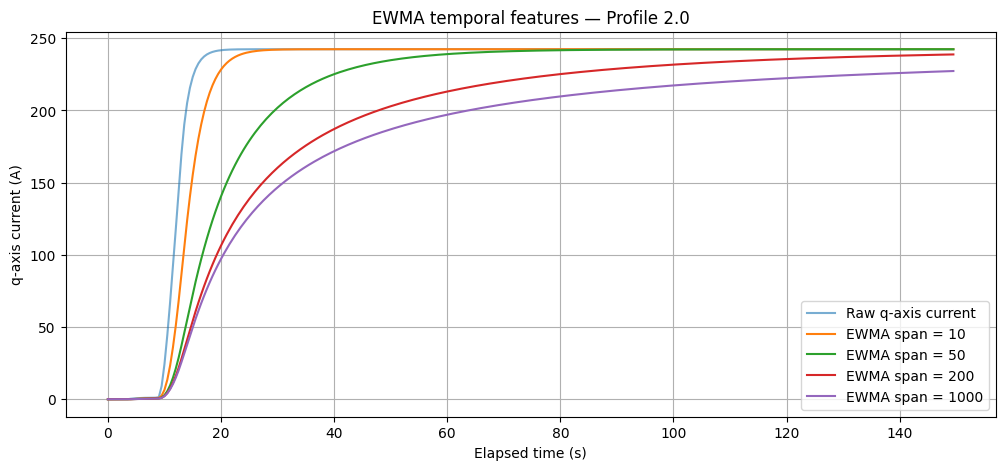

In [ ]:
import matplotlib.pyplot as plt

# Plot q-axis current for one profile
pid = demo_ids[0]

mask = demo_df["profile_id"] == pid

time = np.arange(mask.sum()) / 2

plt.figure(figsize=(12, 5))

# Original q-axis current
plt.plot(
    time,
    X_temporal.loc[mask, "i_q"].to_numpy(),
    label="Raw q-axis current",
    alpha=0.6
)

# Compare EWMA spans
for span in [10, 50, 200, 1000]:
    plt.plot(
        time,
        X_temporal.loc[
            mask, f"i_q_ewma_s{span}"
        ].to_numpy(),
        label=f"EWMA span = {span}"
    )

plt.xlabel("Elapsed time (s)")
plt.ylabel("q-axis current (A)")
plt.title(f"EWMA temporal features — Profile {pid}")
plt.legend()
plt.grid(True)
plt.show()

# 3 fold cross validation


In [ ]:

import pandas as pd
from sklearn.model_selection import StratifiedKFold

# =====================================================
# STEP 6.1A — Restore dataset and locked test profiles
# =====================================================

raw_df = pd.read_csv(
    "/content/PMSM Electric Motor Temperature Measurement.csv"
)

test_ids = [
    13, 16, 23, 24, 29, 42, 44,
    47, 53, 56, 62, 67, 71, 78
]

train_df = raw_df[
    ~raw_df["profile_id"].isin(test_ids)
].copy()

test_df = raw_df[
    raw_df["profile_id"].isin(test_ids)
].copy()

assert len(train_df) == 1055198
assert len(test_df) == 275618

print("PASS: Original development/test split restored")


# =====================================================
# STEP 6.1B — Summarise development profiles
# =====================================================

profile_cv = (
    train_df.groupby("profile_id")["pm"]
    .agg(
        observations="size",
        pm_min="min",
        pm_max="max"
    )
    .reset_index()
    .sort_values("profile_id")
    .reset_index(drop=True)
)

# Divide development profiles into three
# groups based on maximum PM temperature
profile_cv["temperature_group"] = pd.qcut(
    profile_cv["pm_max"],
    q=3,
    labels=["Low", "Medium", "High"]
)


# =====================================================
# STEP 6.1C — Stratified 3-fold split by profile
# =====================================================

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

profile_cv["cv_fold"] = -1

for fold, (_, val_pos) in enumerate(
    skf.split(
        profile_cv[["pm_max"]],
        profile_cv["temperature_group"]
    ),
    start=1
):
    profile_cv.loc[val_pos, "cv_fold"] = fold

print("\nPASS: Three validation folds created")


# =====================================================
# STEP 6.1D — Verify grouping and partition integrity
# =====================================================

assert len(profile_cv) == 55
assert profile_cv["profile_id"].is_unique
assert profile_cv["cv_fold"].isin([1, 2, 3]).all()

development_ids = set(profile_cv["profile_id"])

assert development_ids.isdisjoint(set(test_ids))

for fold in [1, 2, 3]:

    val_ids = set(
        profile_cv.loc[
            profile_cv["cv_fold"] == fold,
            "profile_id"
        ]
    )

    fold_train_ids = development_ids - val_ids

    assert val_ids.isdisjoint(fold_train_ids)
    assert val_ids.isdisjoint(set(test_ids))

    print(f"\nFold {fold}:")
    print("Training profiles:", len(fold_train_ids))
    print("Validation profiles:", len(val_ids))

print("\nPASS: No profile leakage detected")


# =====================================================
# STEP 6.1E — Save cross-validation assignments
# =====================================================

profile_cv.to_csv(
    "profile_cv_assignments.csv",
    index=False
)

print("\nSaved: profile_cv_assignments.csv")


PASS: Original development/test split restored

PASS: Three validation folds created

Fold 1:
Training profiles: 36
Validation profiles: 19

Fold 2:
Training profiles: 37
Validation profiles: 18

Fold 3:
Training profiles: 37
Validation profiles: 18

PASS: No profile leakage detected

Saved: profile_cv_assignments.csv


In [ ]:

# =====================================================
# STEP 6.1F — Evaluate fold balance
# =====================================================

print("Temperature-group distribution:")

display(
    pd.crosstab(
        profile_cv["cv_fold"],
        profile_cv["temperature_group"]
    )
)

# Calculate number of observations and recording hours
fold_summary = (
    profile_cv.groupby("cv_fold")
    .agg(
        profiles=("profile_id", "size"),
        observations=("observations", "sum"),
        min_pm=("pm_min", "min"),
        max_pm=("pm_max", "max")
    )
)

fold_summary["duration_hours"] = (
    fold_summary["observations"] / 7200
)

print("\nValidation-fold summary:")
display(fold_summary)

# All development observations must be assigned
assert fold_summary["observations"].sum() == len(train_df)

print("\nPASS: All development observations assigned")


Temperature-group distribution:


temperature_group,Low,Medium,High
cv_fold,,,
1,7,6,6
2,6,5,7
3,6,6,6



Validation-fold summary:


,profiles,observations,min_pm,max_pm,duration_hours
cv_fold,,,,,
1,19,401114,21.213623,109.333847,55.710278
2,18,362087,20.856956,105.948723,50.289861
3,18,291997,22.888792,99.396629,40.555139



PASS: All development observations assigned
